In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib
import warnings

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = "indian-job-market-dataset-2025.xlsx"

df = pd.read_excel(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (97929, 17)

Column names:
['title', 'jobId', 'currency', 'jobUploaded', 'companyName', 'tagsAndSkills', 'experience', 'salary', 'location', 'companyId', 'ReviewsCount', 'AggregateRating', 'jobDescription', 'minimumSalary', 'maximumSalary', 'minimumExperience', 'maximumExperience']


,title,jobId,currency,jobUploaded,companyName,tagsAndSkills,experience,salary,location,companyId,ReviewsCount,AggregateRating,jobDescription,minimumSalary,maximumSalary,minimumExperience,maximumExperience
0,Sr. HR Recruiter (NON IT),270925008041,INR,6 Days Ago,Orion,"Communication,Manpower,Staffing,Convincing Pow...",2-4 Yrs,2-4 Lacs PA,Kolkata(Chinar Park),645563,NaN,NaN,Preferred candidate profile . .,200000.0,400000.0,2.0,4.0
1,Fire And Safety Officer,270925007584,INR,6 Days Ago,"Apollo Hospitals International Limited, Ahmedabad","Safety Officer Activities,Fire Protection,Fire...",6-11 Yrs,3-5 Lacs PA,"Gandhinagar, Ahmedabad",14072,5162.0,4.0,"Ensure active Fire Protection System,such as F...",300000.0,500000.0,6.0,11.0
2,Opening For Performance Marketing - Chennai,270925007492,INR,6 Days Ago,TVS Credit Services Ltd,"Performance Marketing,User Acquisition,growth ...",12-18 Yrs,Not disclosed,Chennai,1324750,2892.0,4.2,MBA Marketing (preferred Tier II or III B- Sch...,0.0,0.0,12.0,18.0
3,Medical Billing Executive,270925007443,INR,6 Days Ago,GNR Global Services,"Fluent English,Spoken English,Good English Com...",0-3 Yrs,"70,000-2 Lacs PA","Mohali, Chandigarh, Kharar, Zirakpur",123804403,NaN,NaN,Job Title-Medical Billing Executive\nLocation-...,70000.0,200000.0,0.0,3.0
4,Senior Group Product Manager - CNS Therapy,270925007430,INR,6 Days Ago,Cadila Pharmaceuticals,"Product Marketing,CNS,Product Management,Nephr...",5-10 Yrs,8-18 Lacs PA,Ahmedabad,14957,2134.0,3.4,Principal Tasks & Responsibilities : (Please w...,800000.0,1800000.0,5.0,10.0


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nSalary column statistics:")
display(df[["minimumSalary", "maximumSalary"]].describe())

print("\nCurrency distribution:")
display(df["currency"].value_counts(dropna=False))

print("\nSalary disclosure:")
print("Jobs with salary disclosed:", (df["maximumSalary"] > 0).sum())
print("Jobs without salary disclosed:", (df["maximumSalary"] <= 0).sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 97929 entries, 0 to 97928
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   title              97929 non-null  str    
 1   jobId              97929 non-null  int64  
 2   currency           97929 non-null  str    
 3   jobUploaded        97929 non-null  str    
 4   companyName        97925 non-null  str    
 5   tagsAndSkills      97358 non-null  str    
 6   experience         95824 non-null  str    
 7   salary             97929 non-null  str    
 8   location           97929 non-null  str    
 9   companyId          97929 non-null  int64  
 10  ReviewsCount       62677 non-null  float64
 11  AggregateRating    62677 non-null  float64
 12  jobDescription     97929 non-null  str    
 13  minimumSalary      97358 non-null  float64
 14  maximumSalary      97358 non-null  float64
 15  minimumExperience  97358 non-null  float64
 16  maximumExper

,Missing Values
title,0
jobId,0
currency,0
jobUploaded,0
companyName,4
tagsAndSkills,571
experience,2105
salary,0
location,0
companyId,0



Salary column statistics:


,minimumSalary,maximumSalary
count,9.735800e+04,9.735800e+04
mean,1.983092e+05,3.186096e+05
std,5.640765e+05,8.417336e+05
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00
75%,2.000000e+05,3.750000e+05
max,7.000000e+07,9.500000e+07



Currency distribution:


currency
INR    97800
USD      129
Name: count, dtype: int64


Salary disclosure:
Jobs with salary disclosed: 33237
Jobs without salary disclosed: 64121


In [4]:
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Clean column names
df_clean.columns = df_clean.columns.str.strip()

# Keep INR records only
df_clean = df_clean[
    df_clean["currency"].astype(str).str.upper().str.strip() == "INR"
].copy()

# Convert salary and experience columns to numeric
numeric_columns = [
    "minimumSalary",
    "maximumSalary",
    "minimumExperience",
    "maximumExperience",
    "ReviewsCount",
    "AggregateRating"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Exclude jobs without a disclosed salary range
df_clean = df_clean[
    (df_clean["minimumSalary"] > 0) &
    (df_clean["maximumSalary"] >= df_clean["minimumSalary"])
].copy()

# Create the prediction target: midpoint of the annual salary range
df_clean["target_salary"] = (
    df_clean["minimumSalary"] + df_clean["maximumSalary"]
) / 2

# Create a midpoint experience feature
df_clean["experience_years"] = (
    df_clean["minimumExperience"] +
    df_clean["maximumExperience"]
) / 2

# Replace invalid experience values
df_clean.loc[
    df_clean["experience_years"] < 0,
    "experience_years"
] = np.nan

# Fill missing text fields
for col in ["title", "tagsAndSkills", "location"]:
    df_clean[col] = df_clean[col].fillna("Unknown").astype(str)

# Remove impossible or invalid salary targets
df_clean = df_clean[
    np.isfinite(df_clean["target_salary"]) &
    (df_clean["target_salary"] > 0)
].copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

display(
    df_clean[
        ["title", "tagsAndSkills", "location",
         "experience_years", "target_salary"]
    ].head()
)

Original dataset: (97929, 17)
Cleaned dataset: (33118, 19)


,title,tagsAndSkills,location,experience_years,target_salary
0,Sr. HR Recruiter (NON IT),"Communication,Manpower,Staffing,Convincing Pow...",Kolkata(Chinar Park),3.0,300000.0
1,Fire And Safety Officer,"Safety Officer Activities,Fire Protection,Fire...","Gandhinagar, Ahmedabad",8.5,400000.0
3,Medical Billing Executive,"Fluent English,Spoken English,Good English Com...","Mohali, Chandigarh, Kharar, Zirakpur",1.5,135000.0
4,Senior Group Product Manager - CNS Therapy,"Product Marketing,CNS,Product Management,Nephr...",Ahmedabad,7.5,1300000.0
5,Senior Accountant,"Tds Filing,ITR,Gst Filing,Balance Sheet Finali...","Noida, Greater Noida",12.5,475000.0


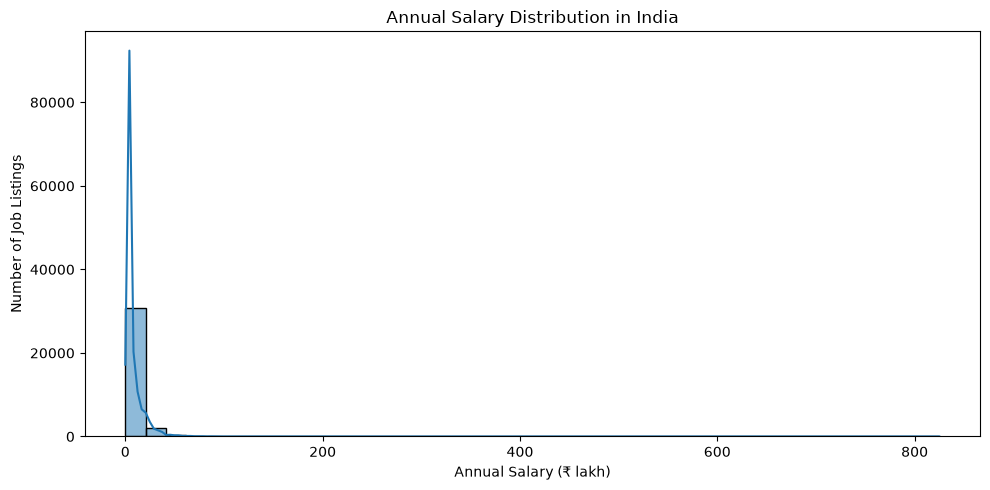

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["target_salary"] / 100000,
    bins=40,
    kde=True
)

plt.title("Annual Salary Distribution in India")
plt.xlabel("Annual Salary (₹ lakh)")
plt.ylabel("Number of Job Listings")
plt.tight_layout()
plt.show()

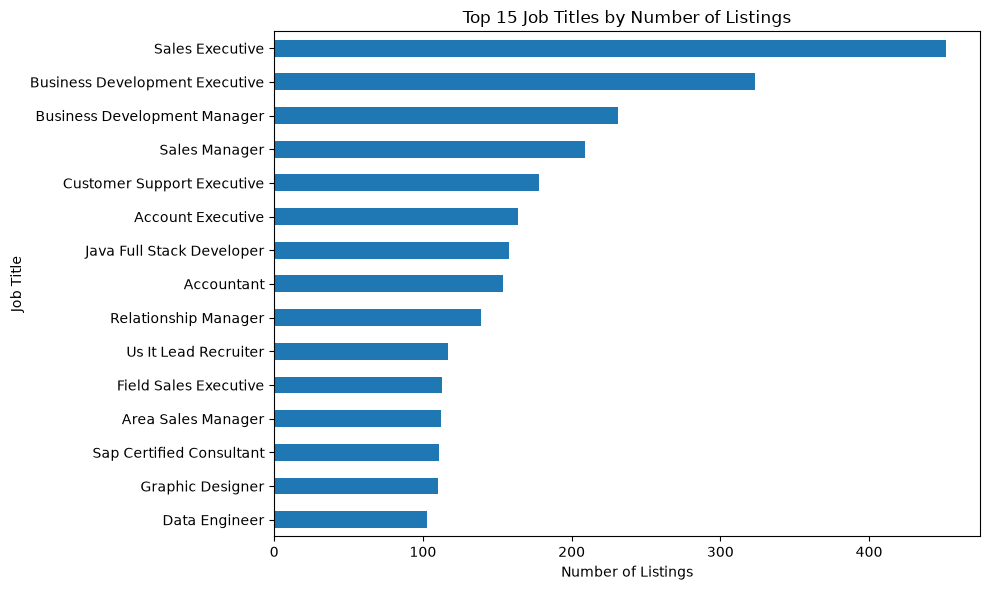

In [6]:
top_jobs = df_clean["title"].value_counts().head(15)

plt.figure(figsize=(10, 6))
top_jobs.sort_values().plot(kind="barh")

plt.title("Top 15 Job Titles by Number of Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

,title,Median_Salary,Number_of_Jobs
0,Data Solution Architect,2500000.0,37
1,Solution Architect,2500000.0,59
2,Data Scientist,2250000.0,23
3,Senior Software Engineer,2250000.0,22
4,Senior Data Engineer,2000000.0,40
5,Big Data Engineer,2000000.0,59
6,Data Engineer,1925000.0,103
7,Java Full Stack Developer,1875000.0,158
8,Servicenow Developer,1500000.0,22
9,Java Developer,1500000.0,71


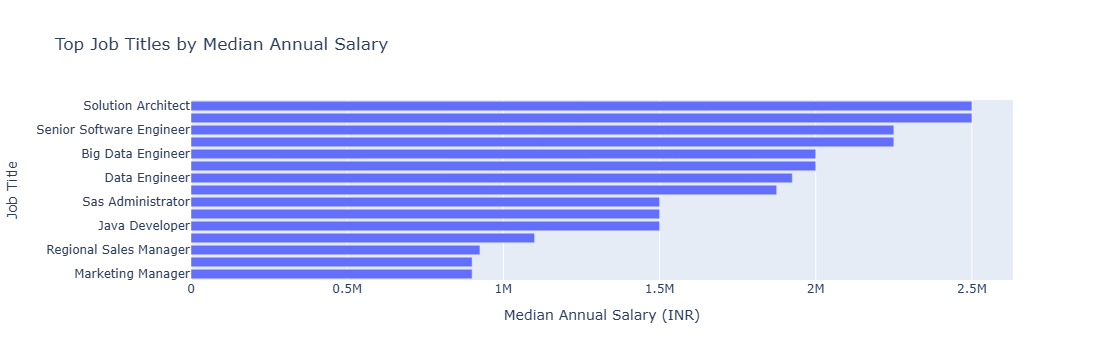

In [7]:
job_salary = (
    df_clean.groupby("title")
    .agg(
        Median_Salary=("target_salary", "median"),
        Number_of_Jobs=("target_salary", "size")
    )
    .query("Number_of_Jobs >= 20")
    .sort_values("Median_Salary", ascending=False)
    .head(15)
    .reset_index()
)

display(job_salary)

fig = px.bar(
    job_salary.sort_values("Median_Salary"),
    x="Median_Salary",
    y="title",
    orientation="h",
    title="Top Job Titles by Median Annual Salary",
    labels={
        "Median_Salary": "Median Annual Salary (INR)",
        "title": "Job Title"
    }
)

fig.show()

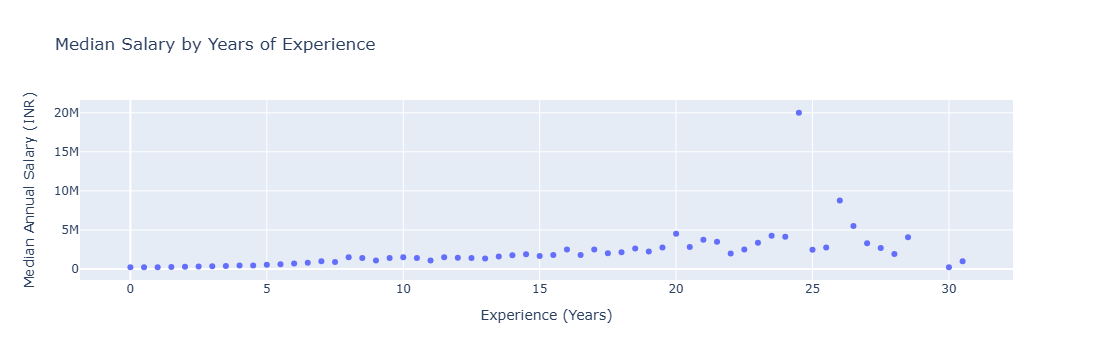

In [8]:
experience_summary = (
    df_clean.groupby("experience_years")["target_salary"]
    .median()
    .reset_index()
)

fig = px.scatter(
    experience_summary,
    x="experience_years",
    y="target_salary",
    title="Median Salary by Years of Experience",
    labels={
        "experience_years": "Experience (Years)",
        "target_salary": "Median Annual Salary (INR)"
    }
)

fig.show()

In [9]:
# Combine job title and required skills into one text feature
df_model = df_clean.copy()

df_model["job_text"] = (
    df_model["title"] + " " +
    df_model["tagsAndSkills"]
)

# Select the input features
feature_columns = [
    "job_text",
    "location",
    "minimumExperience",
    "maximumExperience",
    "ReviewsCount",
    "AggregateRating"
]

X = df_model[feature_columns].copy()
y = df_model["target_salary"].copy()

# Remove records with missing or invalid targets
valid = y.notna() & np.isfinite(y) & (y > 0)
X = X.loc[valid].copy()
y = y.loc[valid].copy()

text_column = "job_text"
categorical_columns = ["location"]

numeric_columns = [
    "minimumExperience",
    "maximumExperience",
    "ReviewsCount",
    "AggregateRating"
]

print("Input features:", X.columns.tolist())
print("Number of records:", len(X))
print("Number of input features:", X.shape[1])

display(X.head())

Input features: ['job_text', 'location', 'minimumExperience', 'maximumExperience', 'ReviewsCount', 'AggregateRating']
Number of records: 33118
Number of input features: 6


,job_text,location,minimumExperience,maximumExperience,ReviewsCount,AggregateRating
0,"Sr. HR Recruiter (NON IT) Communication,Manpow...",Kolkata(Chinar Park),2.0,4.0,NaN,NaN
1,Fire And Safety Officer Safety Officer Activit...,"Gandhinagar, Ahmedabad",6.0,11.0,5162.0,4.0
3,"Medical Billing Executive Fluent English,Spoke...","Mohali, Chandigarh, Kharar, Zirakpur",0.0,3.0,NaN,NaN
4,Senior Group Product Manager - CNS Therapy Pr...,Ahmedabad,5.0,10.0,2134.0,3.4
5,"Senior Accountant Tds Filing,ITR,Gst Filing,Ba...","Noida, Greater Noida",10.0,15.0,NaN,NaN


In [10]:
text_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=500,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2
        )
    )
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=20
        )
    )
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("text", text_pipeline, text_column),
        ("location", categorical_pipeline, categorical_columns),
        ("numeric", numeric_pipeline, numeric_columns)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 26494
Testing records: 6624


In [12]:
models = {
    "Ridge Regression": Ridge(alpha=10),

    "Random Forest": RandomForestRegressor(
        n_estimators=60,
        max_depth=18,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

# Transform target for training
y_train_log = np.log1p(y_train)

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    print("Training:", model_name)

    pipeline.fit(X_train, y_train_log)

    # Predict log salary, then convert back to INR
    predicted_log = pipeline.predict(X_test)
    predictions = np.maximum(np.expm1(predicted_log), 0)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "MAE_INR": mae,
        "RMSE_INR": rmse,
        "R2_Score": r2
    })

results_df = pd.DataFrame(results).sort_values("MAE_INR")

display(results_df.round(3))

Training: Ridge Regression
Training: Random Forest


,Model,MAE_INR,RMSE_INR,R2_Score
1,Random Forest,289840.678,805215.908,0.418
0,Ridge Regression,295804.843,784675.662,0.447


In [13]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

predicted_log = best_model.predict(X_test)
predicted_salary = np.maximum(np.expm1(predicted_log), 0)

comparison = pd.DataFrame({
    "Actual_Salary_INR": y_test.values,
    "Predicted_Salary_INR": predicted_salary
})

print("Best model by MAE:", best_model_name)

display(comparison.head(15))

Best model by MAE: Random Forest


,Actual_Salary_INR,Predicted_Salary_INR
0,750000.0,4.781657e+05
1,375000.0,3.245685e+05
2,400000.0,6.619202e+05
3,210000.0,2.463180e+05
4,80000.0,6.770238e+05
5,237500.0,3.350955e+05
6,625000.0,7.012515e+05
7,600000.0,2.938529e+05
8,450000.0,3.328292e+05
9,450000.0,3.595731e+05


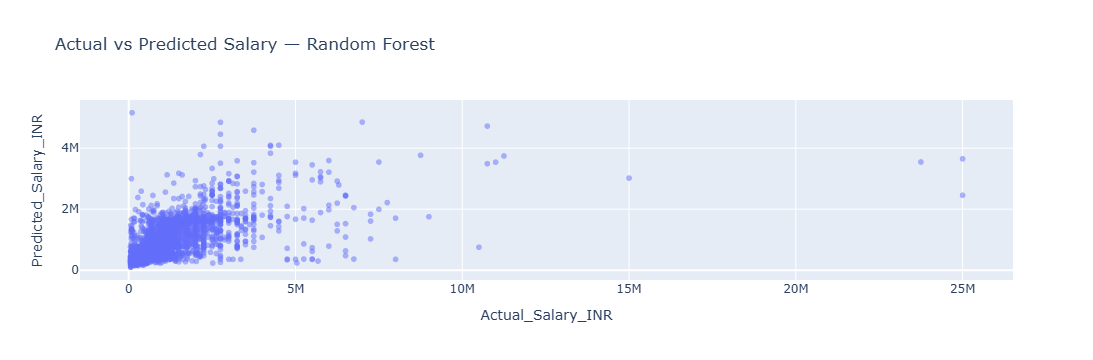

In [14]:
fig = px.scatter(
    comparison,
    x="Actual_Salary_INR",
    y="Predicted_Salary_INR",
    title=f"Actual vs Predicted Salary — {best_model_name}",
    opacity=0.5
)

fig.show()

In [15]:
comparison["Absolute_Error_INR"] = abs(
    comparison["Actual_Salary_INR"] -
    comparison["Predicted_Salary_INR"]
)

display(
    comparison["Absolute_Error_INR"]
    .describe()
    .to_frame("Absolute Prediction Error (INR)")
)

,Absolute Prediction Error (INR)
count,6.624000e+03
mean,2.898407e+05
std,7.512990e+05
min,6.028786e+01
25%,4.258055e+04
50%,1.026873e+05
75%,2.517812e+05
max,2.254222e+07


In [16]:
import ipywidgets as widgets
from IPython.display import display, clear_output

job_title_input = widgets.Text(
    value="Data Engineer",
    description="Job title:",
    layout=widgets.Layout(width="500px")
)

skills_input = widgets.Textarea(
    value="Python, SQL, ETL, Spark, AWS",
    description="Skills:",
    layout=widgets.Layout(width="500px", height="80px")
)

location_input = widgets.Text(
    value="Bengaluru",
    description="Location:",
    layout=widgets.Layout(width="500px")
)

min_exp_input = widgets.BoundedFloatText(
    value=2, min=0, max=40,
    description="Min years:"
)

max_exp_input = widgets.BoundedFloatText(
    value=4, min=0, max=40,
    description="Max years:"
)

reviews_input = widgets.BoundedFloatText(
    value=100, min=0, max=1000000,
    description="Reviews:"
)

rating_input = widgets.BoundedFloatText(
    value=4.0, min=0, max=5,
    description="Rating:"
)

predict_button = widgets.Button(
    description="Predict Salary",
    button_style="success"
)

prediction_output = widgets.Output()

def predict_salary(button):

    with prediction_output:
        clear_output(wait=True)

        if min_exp_input.value > max_exp_input.value:
            print("Maximum experience must be greater than or equal to minimum experience.")
            return

        new_job = pd.DataFrame([{
            "job_text": (
                job_title_input.value + " " +
                skills_input.value
            ),
            "location": location_input.value,
            "minimumExperience": min_exp_input.value,
            "maximumExperience": max_exp_input.value,
            "ReviewsCount": reviews_input.value,
            "AggregateRating": rating_input.value
        }])

        log_prediction = best_model.predict(new_job)[0]
        salary_prediction = max(np.expm1(log_prediction), 0)

        print("Job Title:", job_title_input.value)
        print("Location:", location_input.value)
        print("Selected Model:", best_model_name)
        print(f"Estimated Annual Salary: ₹{salary_prediction:,.0f}")
        print(f"Estimated Monthly Equivalent: ₹{salary_prediction / 12:,.0f}")

predict_button.on_click(predict_salary)

display(widgets.VBox([
    widgets.HTML("<h3>Indian Job Market — Salary Prediction</h3>"),
    job_title_input,
    skills_input,
    location_input,
    min_exp_input,
    max_exp_input,
    reviews_input,
    rating_input,
    predict_button,
    prediction_output
]))

In [17]:
# Use the cleaned salary dataset
dashboard_data = df_clean.copy()

# Create role and location filters
role_options = ["All"] + sorted(
    dashboard_data["title"].dropna().unique().tolist()
)

location_options = ["All"] + sorted(
    dashboard_data["location"].dropna().unique().tolist()
)

role_dropdown = widgets.Dropdown(
    options=role_options,
    value="All",
    description="Job title:"
)

location_dropdown = widgets.Dropdown(
    options=location_options,
    value="All",
    description="Location:"
)

dashboard_output = widgets.Output()

def update_dashboard(change=None):

    with dashboard_output:
        clear_output(wait=True)

        filtered = dashboard_data.copy()

        if role_dropdown.value != "All":
            filtered = filtered[
                filtered["title"] == role_dropdown.value
            ]

        if location_dropdown.value != "All":
            filtered = filtered[
                filtered["location"] == location_dropdown.value
            ]

        if filtered.empty:
            print("No records found for the selected filters.")
            return

        # Key performance indicators
        display(pd.DataFrame({
            "Metric": [
                "Number of Jobs",
                "Average Annual Salary",
                "Median Annual Salary"
            ],
            "Value": [
                f"{len(filtered):,}",
                f"₹{filtered['target_salary'].mean():,.0f}",
                f"₹{filtered['target_salary'].median():,.0f}"
            ]
        }))

        # Salary distribution
        fig = px.histogram(
            filtered,
            x="target_salary",
            nbins=30,
            title="Annual Salary Distribution",
            labels={"target_salary": "Annual Salary (INR)"}
        )
        fig.show()

        # Top job titles by median salary
        role_summary = (
            filtered.groupby("title")
            .agg(
                Median_Salary=("target_salary", "median"),
                Job_Count=("target_salary", "size")
            )
            .query("Job_Count >= 5")
            .sort_values("Median_Salary", ascending=False)
            .head(10)
            .reset_index()
        )

        if not role_summary.empty:
            fig = px.bar(
                role_summary,
                x="Median_Salary",
                y="title",
                orientation="h",
                title="Top 10 Job Titles by Median Salary",
                labels={
                    "Median_Salary": "Median Annual Salary (INR)",
                    "title": "Job Title"
                }
            )
            fig.show()

        # Top locations by median salary
        location_summary = (
            filtered.groupby("location")
            .agg(
                Median_Salary=("target_salary", "median"),
                Job_Count=("target_salary", "size")
            )
            .query("Job_Count >= 5")
            .sort_values("Median_Salary", ascending=False)
            .head(10)
            .reset_index()
        )

        if not location_summary.empty:
            fig = px.bar(
                location_summary,
                x="Median_Salary",
                y="location",
                orientation="h",
                title="Top 10 Locations by Median Salary",
                labels={
                    "Median_Salary": "Median Annual Salary (INR)",
                    "location": "Location"
                }
            )
            fig.show()

role_dropdown.observe(update_dashboard, names="value")
location_dropdown.observe(update_dashboard, names="value")

display(widgets.VBox([
    widgets.HTML("<h2>Indian Job Market Dashboard</h2>"),
    role_dropdown,
    location_dropdown,
    dashboard_output
]))

update_dashboard()

In [18]:
# Save cleaned data
df_clean.to_csv("cleaned_indian_job_market.csv", index=False)

# Save model evaluation results
results_df.to_csv("salary_model_comparison.csv", index=False)

# Save the selected trained model
joblib.dump(best_model, "indian_salary_prediction_model.pkl")

print("Project outputs saved successfully!")

Project outputs saved successfully!
